## Overview

Pharmaceutical research generates vast amounts of scientific literature containing valuable insights for drug development and experimental design. However, extracting and comparing information across publications can be time-consuming.

This project leverages **Qwen2.5-3B-Instruct**, a locally deployed Large Language Model (LLM), to automatically extract key research variables from scientific papers and transform unstructured text into a **structured, analysis-ready dataset**.

Each row represents a publication, while each column corresponds to a variable of interest. Missing or unavailable information is represented as `null`.

### 01 | Project Configuration

> **Setup** · Define the project directories and locate the scientific publications to be processed.

The output directory is automatically created to store the extracted datasets.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

pdf_files = sorted(RAW_DATA_DIR.glob("*.pdf"))

if not pdf_files:
    raise FileNotFoundError(f"No PDF files found in {RAW_DATA_DIR}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Number of PDF files: {len(pdf_files)}")

for pdf in pdf_files:
    print(f"- {pdf.name}")

Project root: c:\Users\lydia\Desktop\LLM-Based-Pharma-Data-Extraction
Number of PDF files: 6
- fpsyg-08-00308.pdf
- fpsyg-09-01240.pdf
- fpsyg-11-01354.pdf
- fpsyg-12-639236.pdf
- fpsyt-14-1301143.pdf
- fpubh-10-1045777.pdf


### 02 | PDF Text Extraction

> **Extraction** · Extract textual content from scientific publications using PyMuPDF.

Each PDF is processed page by page, and its extracted text is stored in a dictionary for subsequent LLM-based analysis.

In [2]:
import fitz

def extract_pdf_text(pdf_path):
    """
    Extract text from all pages of a PDF document.
    """
    pages = []

    with fitz.open(pdf_path) as doc:
        for page in doc:
            pages.append(page.get_text(sort=True))

    return "\n".join(pages)


documents = {}

for pdf_path in pdf_files:
    text = extract_pdf_text(pdf_path)

    documents[pdf_path.name] = text

    print(
        f"{pdf_path.name}: "
        f"{len(text):,} characters extracted"
    )

c:\Users\lydia\Desktop\LLM-Based-Pharma-Data-Extraction\.venv\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


fpsyg-08-00308.pdf: 109,125 characters extracted
fpsyg-09-01240.pdf: 142,856 characters extracted
fpsyg-11-01354.pdf: 73,302 characters extracted
fpsyg-12-639236.pdf: 105,142 characters extracted
fpsyt-14-1301143.pdf: 58,456 characters extracted
fpubh-10-1045777.pdf: 64,731 characters extracted


### 03 | Local LLM Initialization

> **Model Setup** · Load Qwen2.5-3B-Instruct locally using Hugging Face Transformers and PyTorch.

The model is configured with **4-bit NF4 quantization** to reduce GPU memory usage, enabling efficient inference on consumer-grade hardware.

In [3]:
import json
import re
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16
)

model.eval()

print("LLM loaded successfully!")
print(f"GPU: {torch.cuda.get_device_name(0)}")

W1107 15:14:42.925000 31212 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1107 15:14:47.305000 31212 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

LLM loaded successfully!
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


### 04 | Extraction Schema

> **Feature Definition** · Define the research variables to be extracted from each scientific publication.

The schema includes **13 key variables** covering publication metadata, experimental design, methodology, and research findings. Missing or unavailable information is represented as `null`.

In [4]:
EXTRACTION_FIELDS = [
    "title",
    "authors",
    "publication_year",
    "doi",
    "research_type",
    "research_objective",
    "methodology",
    "sample_size",
    "intervention",
    "control_group",
    "main_findings",
    "limitations",
    "conclusions"
]

### 05 | Prompt Engineering

> **Instruction Design** · Define a structured prompt to guide the LLM in extracting relevant information from scientific publications.

The prompt specifies the extraction schema, field definitions, and output constraints to ensure consistent **JSON responses**, minimize hallucinations, and handle missing information using `null` values.

In [9]:
SYSTEM_PROMPT = """
You are an expert scientific information extraction assistant.

Extract structured information from scientific research papers.

Rules:
1. Extract information only from the provided document excerpt.
2. Do not invent or assume missing information.
3. Return null when information is missing or not applicable.
4. Return ONLY a valid JSON object, without explanations or Markdown formatting.
5. Use exactly the requested keys.
6. Do not confuse cited studies with the original research.
7. For theoretical papers, experimental variables should be null
   unless original experiments are reported.
8. Use integers for publication_year when applicable.
9. Use integers for sample_size when a single sample is reported.
10. For multiple experiments, preserve the individual sample sizes.
11. Use strings for all other non-null fields.
"""

def create_prompt(document_text):

    schema = {field: None for field in EXTRACTION_FIELDS}

    return f"""
Extract the following variables from this scientific paper excerpt:

{json.dumps(schema, indent=2)}

Definitions:
- title: Full paper title.
- authors: Authors of the paper.
- publication_year: Publication year.
- doi: Digital Object Identifier.
- research_type: Type of research.
- research_objective: Main research objective.
- methodology: Methods used.
- sample_size: Number of participants in original experiments.
- intervention: Intervention studied.
- control_group: Control condition or group.
- main_findings: Main findings.
- limitations: Explicitly reported limitations.
- conclusions: Main conclusions.

Important:
- This text is an excerpt from a larger scientific publication.
- Extract only information explicitly supported by this excerpt.
- Do not infer missing information from other sections.
- Return null for fields not supported by this excerpt.
- Do not confuse cited studies with original research.
- Return a valid JSON object only.

DOCUMENT EXCERPT:
{document_text}
"""

### 06 | LLM Inference

> **Information Extraction** · Process scientific publications using a locally deployed Large Language Model.

Documents are divided into manageable text chunks to overcome input length constraints. Each chunk is independently analyzed using **Qwen2.5-3B-Instruct**, enabling information extraction across the complete publication.

In [10]:
MAX_DOCUMENT_TOKENS = 1800
MAX_INPUT_TOKENS = 3000
MAX_NEW_TOKENS = 900


def split_document(document_text):
    """
    Split a scientific document into token-based chunks.
    """

    tokens = tokenizer.encode(
        document_text,
        add_special_tokens=False
    )

    chunks = []

    for start in range(0, len(tokens), MAX_DOCUMENT_TOKENS):

        chunk_tokens = tokens[
            start:start + MAX_DOCUMENT_TOKENS
        ]

        chunk_text = tokenizer.decode(
            chunk_tokens,
            skip_special_tokens=True
        )

        chunks.append(chunk_text)

    return chunks


def extract_information(document_text):
    """
    Extract structured information from a document excerpt
    using the locally deployed language model.
    """

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": create_prompt(document_text)
        }
    ]

    # Apply chat template
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    # Move tensors to GPU
    inputs = {
        key: value.to(model.device)
        for key, value in inputs.items()
    }

    input_length = inputs["input_ids"].shape[-1]

    if input_length > MAX_INPUT_TOKENS:
        raise ValueError(
            f"Prompt exceeds token limit: {input_length} tokens."
        )

    # Generate response
    with torch.inference_mode():

        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode generated response
    response = tokenizer.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    )

    return response

### 07 | JSON Parsing

> **Output Processing** · Parse the LLM-generated response into a structured Python dictionary.

The function extracts the JSON object, maps its values to the predefined extraction schema, and handles invalid responses to ensure consistent downstream processing.

In [11]:
def parse_response(response):

    try:
        match = re.search(r"\{.*\}", response, re.DOTALL)

        if not match:
            raise ValueError("No JSON found")

        data = json.loads(match.group())

        return {
            field: data.get(field)
            for field in EXTRACTION_FIELDS
        }

    except (json.JSONDecodeError, ValueError) as error:
        print(f"Parsing error: {error}")
        return None


def merge_extractions(extractions):
    """
    Merge extracted information from multiple document chunks.

    Keep the first non-null value for each field and
    record conflicting values for later review.
    """

    merged = {
        field: None
        for field in EXTRACTION_FIELDS
    }

    conflicts = {}

    for extraction in extractions:

        for field in EXTRACTION_FIELDS:

            value = extraction.get(field)

            if value is None or value == "":
                continue

            if merged[field] is None:
                merged[field] = value

            elif merged[field] != value:

                conflicts.setdefault(field, [])

                if value not in conflicts[field]:
                    conflicts[field].append(value)

    return merged, conflicts

### 08 | Single-Document Extraction Test

> **Model Validation** · Test the extraction pipeline on a single scientific publication before processing the complete dataset.

The first document is passed to the LLM to inspect the generated JSON response and verify the extraction workflow.

In [12]:
# Select the first document
first_filename = next(iter(documents))

print(f"Processing: {first_filename}")

# Split document into chunks
chunks = split_document(documents[first_filename])

print(f"Number of chunks: {len(chunks)}")

# Test extraction on the first chunk
response = extract_information(chunks[0])

print("\nLLM Response:")
print(response)

# Validate JSON
parsed_data = parse_response(response)

if parsed_data is not None:
    print("\nJSON parsed successfully!")
else:
    print("\nJSON parsing failed.")

Processing: fpsyg-08-00308.pdf
Number of chunks: 13

LLM Response:
{
  "title": "Placebo and Nocebo Effects: The Advantage of Measuring Expectations and Psychological Factors",
  "authors": ["Nicole Corsi", "Luana Colloca"],
  "publication_year": 2017,
  "doi": "10.3389/fpsyg.2017.00308",
  "research_type": "Original Research",
  "research_objective": "Investigate the interplay between psychological factors, expectations of low and high pain, and placebo and nocebo effects.",
  "methodology": "Used a well-validated conditioning paradigm with contact heat thermal stimuli. Visual cues alerted participants about pain levels.",
  "sample_size": 46,
  "intervention": "High, medium, and low levels of pain associated with red, yellow, and green cues, respectively.",
  "control_group": null,
  "main_findings": "Robust placebo hypolagesic and nocebo hyperalgesic responses correlated with expectancy of low and high pain. Psychological factors per se did not influence expectations.",
  "limitatio

### 09 | Batch Information Extraction

> **Batch Processing** · Apply the LLM-based extraction pipeline to all scientific publications.

Each document is processed independently, and its structured output is stored alongside the source filename. Failed extractions are tracked separately to ensure reliable dataset generation.

In [13]:
results = []
failed_documents = []
extraction_conflicts = {}

# Process all scientific publications
for filename, text in documents.items():

    print(f"\nProcessing: {filename}")

    # Split document into chunks
    chunks = split_document(text)

    print(f"Total chunks: {len(chunks)}")

    chunk_extractions = []
    chunk_errors = []

    # Extract information from each chunk
    for i, chunk in enumerate(chunks, start=1):

        print(f"  Chunk {i}/{len(chunks)}")

        try:
            response = extract_information(chunk)

            data = parse_response(response)

            if data is not None:
                chunk_extractions.append(data)
            else:
                chunk_errors.append(i)

        except Exception as error:
            print(f"  Error in chunk {i}: {error}")
            chunk_errors.append(i)

    # Require successful extraction from every chunk
    if chunk_errors:

        failed_documents.append({
            "source_file": filename,
            "failed_chunks": chunk_errors
        })

        print(f"Failed chunks: {chunk_errors}")
        continue

    # Merge extracted information
    merged_data, conflicts = merge_extractions(
        chunk_extractions
    )

    merged_data["source_file"] = filename

    results.append(merged_data)

    # Store conflicting values for review
    if conflicts:
        extraction_conflicts[filename] = conflicts

    print("Completed!")

# Processing summary
print("\nExtraction Summary")
print(f"Successfully processed: {len(results)}")
print(f"Failed documents: {len(failed_documents)}")
print(f"Documents with conflicts: {len(extraction_conflicts)}")


Processing: fpsyg-08-00308.pdf
Total chunks: 13
  Chunk 1/13
  Chunk 2/13
  Chunk 3/13
  Chunk 4/13
  Chunk 5/13
  Chunk 6/13
  Chunk 7/13
  Chunk 8/13
  Chunk 9/13
  Chunk 10/13
  Chunk 11/13
  Chunk 12/13
  Chunk 13/13
Completed!

Processing: fpsyg-09-01240.pdf
Total chunks: 16
  Chunk 1/16
  Chunk 2/16
  Chunk 3/16
  Chunk 4/16
  Chunk 5/16
  Chunk 6/16
  Chunk 7/16
  Chunk 8/16
  Chunk 9/16
  Chunk 10/16
  Chunk 11/16
  Chunk 12/16
  Chunk 13/16
  Chunk 14/16
  Chunk 15/16
  Chunk 16/16
Completed!

Processing: fpsyg-11-01354.pdf
Total chunks: 11
  Chunk 1/11
  Chunk 2/11
  Chunk 3/11
  Chunk 4/11
  Chunk 5/11
  Chunk 6/11
  Chunk 7/11
  Chunk 8/11
  Chunk 9/11
  Chunk 10/11
  Chunk 11/11
Completed!

Processing: fpsyg-12-639236.pdf
Total chunks: 16
  Chunk 1/16
  Chunk 2/16
  Chunk 3/16
  Chunk 4/16
  Chunk 5/16
  Chunk 6/16
  Chunk 7/16
  Chunk 8/16
  Chunk 9/16
  Chunk 10/16
  Chunk 11/16
  Chunk 12/16
  Chunk 13/16
  Chunk 14/16
  Chunk 15/16
  Chunk 16/16
Completed!

Processing

### 10 | Dataset Generation

> **Data Structuring** · Consolidate the extracted research information into a structured Pandas DataFrame.

Each row represents a scientific publication, while each column corresponds to a predefined research variable. Missing values are preserved to ensure a consistent dataset structure.

In [14]:
# Verify that all documents were processed
if len(results) != len(documents):
    raise ValueError(
        f"Expected {len(documents)} documents, "
        f"but only {len(results)} were successfully processed."
    )

# Create DataFrame
df = pd.DataFrame(results)

# Define column order
column_order = ["source_file"] + EXTRACTION_FIELDS

df = df.reindex(columns=column_order)


def normalize_value(value):
    """
    Convert nested structures into consistent text representations.
    """

    if isinstance(value, dict):

        return "; ".join(
            f"{key}: {val}"
            for key, val in value.items()
        )

    if isinstance(value, list):

        return "; ".join(
            str(item)
            for item in value
        )

    return value


# Normalize extracted values
for column in EXTRACTION_FIELDS:

    df[column] = df[column].apply(normalize_value)


# Display dataset
display(df)

print(
    f"Dataset shape: "
    f"{df.shape[0]} rows × {df.shape[1]} columns"
)

,source_file,title,authors,publication_year,doi,research_type,research_objective,methodology,sample_size,intervention,control_group,main_findings,limitations,conclusions
0,fpsyg-08-00308.pdf,Placebo and Nocebo Effects: The Advantage of M...,Nicole Corsi; Luana Colloca,2017,10.3389/fpsyg.2017.00308,Original Research,Investigate the interplay between psychologica...,Used a well-validated conditioning paradigm wi...,46,"High, medium, and low levels of pain associate...","No specific control group mentioned, only plac...",Robust placebo hypolagesic and nocebo hyperalg...,No explicit limitations mentioned in the excerpt.,Psychological factors and expectation measures...
1,fpsyg-09-01240.pdf,Application of Bayes’ Theorem in Valuating Dep...,Marco Tommasi; Grazia Ferrara; Aristide Saggino,2018,10.3389/fpsyg.2018.01240,Theoretical,To evaluate the diagnostic accuracy of depress...,Analysis of published works reporting sensitiv...,100,NaN,NaN,None of the tested depression tests can reach ...,No explicit limitations are mentioned in the p...,The application of Bayes' theorem is a valid a...
2,fpsyg-11-01354.pdf,Putting the ‘Art’ Into the ‘Art of Medicine’: ...,Michael H. Bernstein; Cosima Locher; Tobias Ku...,2020,10.3389/fpsyg.2020.01354,Theoretical,To explore the role of artifacts in placebo st...,Classical conditioning paradigm,100,"Conspicuous artifacts (e.g., clothing, office ...",No artifacts,"Non-medical artifacts, such as clinician cloth...",No explicit limitations stated,A careful consideration of artifacts may carry...
3,fpsyg-12-639236.pdf,"Placebo Effects on Stress, but Not on Pain Rep...",Sara Magelssen Vambheim; Hojjat Daniali; Magne...,2021,10.3389/fpsyg.2021.639236,Original Research,To investigate if (i) participant sex and (ii)...,Participants received painful stimulations and...,Experiment One: 59; Experiment Two: 93,Placebo cream with lowered intensity of electr...,Natural History Condition (NHC) in Experiment ...,"No placebo effect was seen on pain. However, t...","Low statistical power, within-subjects design,...",Our findings highlight a distinction between p...
4,fpsyt-14-1301143.pdf,Placebo stimulates neuroplasticity in depressi...,Seymour J; Nigel Mathers,2024,10.3389/fpsyt.2023.1301143,Hypothesis and Theory,Develop the Neuroplasticity Placebo Theory,Literature review,None,Various treatments including electroconvulsive...,Placebo,Neuroplasticity in fronto-limbic areas is the ...,The study by Ashar et al. (21) is an important...,If placebo stimulates neuroplasticity in front...
5,fpubh-10-1045777.pdf,Cognitive distortion based explainable depress...,Bichen Wang; Yanyan Zhao; Xin Lu; Bing Qin,2023,10.3389/fpubh.2022.1045777,Original Research,"Propose a new task, explainable depression det...",Construct a multi-task learning model based on...,100,Semi-supervised learning and fine-tuning a pre...,Depression and control groups,Our experimental results outperform the baseli...,The dataset is still too small for deep learni...,Provide psychologists with effective clues abo...


Dataset shape: 6 rows × 14 columns


### 11 | Data Quality Assessment

> **Quality Analysis** · Evaluate the completeness of the extracted research dataset.

Missing values are analyzed across research variables to identify information gaps and assess the coverage of the LLM-based extraction process.

In [15]:
# Calculate missing values per variable
missing_values = df.isna().sum()

# Calculate completeness percentage
completeness = (1 - df.isna().mean()) * 100

# Create quality report
quality_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Completeness (%)": completeness.round(2)
})

# Sort by completeness
quality_report = quality_report.sort_values(
    by="Completeness (%)",
    ascending=False
)

display(quality_report)

,Missing Values,Completeness (%)
source_file,0,100.00
title,0,100.00
authors,0,100.00
publication_year,0,100.00
doi,0,100.00
research_type,0,100.00
research_objective,0,100.00
methodology,0,100.00
limitations,0,100.00
main_findings,0,100.00


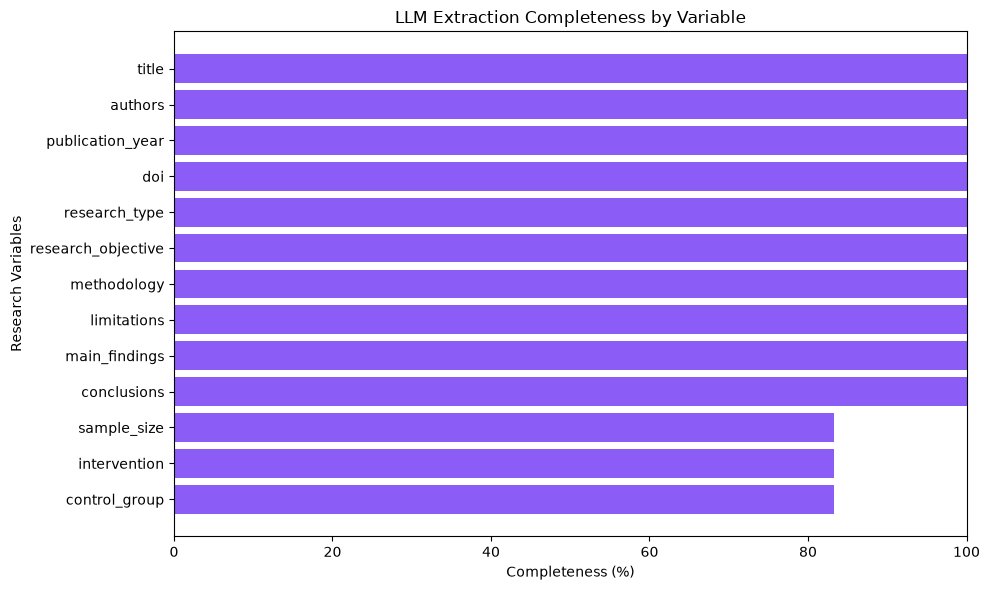

In [16]:
import matplotlib.pyplot as plt

# Exclude source identifier
plot_data = quality_report.drop(
    index="source_file",
    errors="ignore"
)

# Create visualization
plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["Completeness (%)"],
    color="#8B5CF6"
)

plt.xlabel("Completeness (%)")
plt.ylabel("Research Variables")
plt.title("LLM Extraction Completeness by Variable")

plt.xlim(0, 100)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### 12 | Dataset Export

> **Data Export** · Save the structured research dataset in CSV and JSON formats for further analysis.

Both files are stored in the `data/processed/` directory, enabling easy integration with data analysis tools and downstream applications.

In [18]:
csv_path = PROCESSED_DATA_DIR / "pharma_research_dataset.csv"
json_path = PROCESSED_DATA_DIR / "pharma_research_dataset.json"

df.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

df.to_json(
    json_path,
    orient="records",
    indent=4,
    force_ascii=False
)

print(f"CSV exported to: {csv_path}")
print(f"JSON exported to: {json_path}")

CSV exported to: c:\Users\lydia\Desktop\LLM-Based-Pharma-Data-Extraction\data\processed\pharma_research_dataset.csv
JSON exported to: c:\Users\lydia\Desktop\LLM-Based-Pharma-Data-Extraction\data\processed\pharma_research_dataset.json
